### In this session we downloaded a dirty dataset on kaggle : https://www.kaggle.com/datasets/ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training
### we are going to clean it since the principle dataset for models were already clean.

In [1]:
# import library

import pandas as pd
import numpy as np

In [3]:
# upload data

dirty_set = pd.read_csv("dataset/dirty_cafe_sales.csv")
dirty_set.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


In [4]:
dirty_set.tail(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9990,TXN_1538510,Coffee,5,2.0,10.0,Digital Wallet,NaN,2023-05-22
9991,TXN_3897619,Sandwich,3,4.0,12.0,Cash,Takeaway,2023-02-24
9992,TXN_2739140,Smoothie,4,4.0,16.0,UNKNOWN,In-store,2023-07-05
9993,TXN_4766549,Smoothie,2,4.0,NaN,Cash,NaN,2023-10-20
9994,TXN_7851634,UNKNOWN,4,4.0,16.0,NaN,NaN,2023-01-08
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02
9999,TXN_6170729,Sandwich,3,4.0,12.0,Cash,In-store,2023-11-07


In [5]:
dirty_set.shape

(10000, 8)

In [6]:
# For a 10000 x 8 table we have some empty row or unknow values. we can notice it by the 'NaN' or 'UNKNOWN' in some rows 

In [7]:
# lets check for unique values
dirty_set.nunique()

Transaction ID      10000
Item                   10
Quantity                7
Price Per Unit          8
Total Spent            19
Payment Method          5
Location                4
Transaction Date      367
dtype: int64

In [8]:
# since the data set is not full of only numerical values we dont drop thing

#### duplicate value

In [9]:
dirty_set.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool

In [10]:
if dirty_set.duplicated().any() == True:
    print('there is a duplicate value')
else :
    print('There is no duplicate value')

There is no duplicate value


In [11]:
dirty_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [12]:
#Replace ERROR and UNKNOWN by NaN to drop it later

dirty_set = dirty_set.replace(['ERROR', 'UNKNOWN'], np.nan)

dirty_set.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,NaN,3,3.0,9.0,NaN,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,NaN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


In [13]:
# There are missing values in column 1 to 7
# DELETE ALL ROWS with missing values

clean_set = dirty_set.dropna(axis=0, how='any')
clean_set.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
10,TXN_2548360,Salad,5,5.0,25.0,Cash,Takeaway,2023-11-07
12,TXN_7619095,Sandwich,2,4.0,8.0,Cash,In-store,2023-05-03
15,TXN_2847255,Salad,3,5.0,15.0,Credit Card,In-store,2023-11-15
17,TXN_6769710,Juice,2,3.0,6.0,Cash,In-store,2023-02-24
19,TXN_3709394,Juice,4,3.0,12.0,Cash,Takeaway,2023-01-15
21,TXN_3567645,Smoothie,4,4.0,16.0,Credit Card,Takeaway,2023-03-30
22,TXN_5132361,Sandwich,3,4.0,12.0,Digital Wallet,Takeaway,2023-12-01


In [14]:
clean_set.shape

(3089, 8)

### VISUALIZATION

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

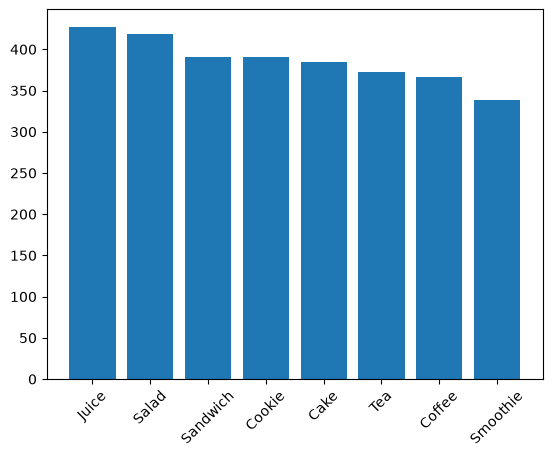

In [16]:
# Plot the most sell item

most_sell = clean_set["Item"].value_counts().sort_values(ascending=False)
index = most_sell.index
frequency = most_sell.values

plt.bar(index.astype(str), frequency)
plt.tick_params(axis="x", rotation=45)
plt.show()

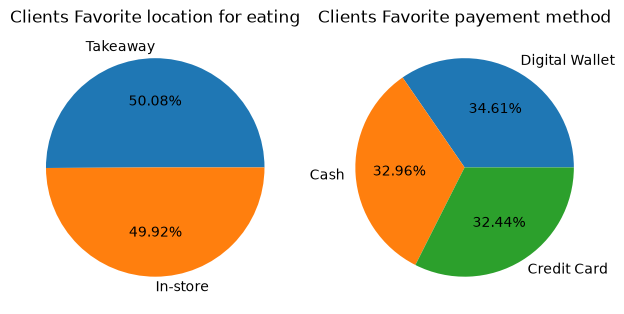

In [17]:
# Do clients prefer take away or in-store ?
# use PIE CHART
fig, ax = plt.subplots(1, 2)

preference_loc = clean_set["Location"].value_counts()
label1 = preference_loc.index

preference_pay = clean_set["Payment Method"].value_counts()
label2 = preference_pay.index

ax[0].pie(preference_loc, labels=label1, autopct = "%1.2f%%")
ax[0].set_title("Clients Favorite location for eating")

ax[1].pie(preference_pay, labels=label2, autopct = "%1.2f%%")
ax[1].set_title("Clients Favorite payement method")

plt.tight_layout()
plt.show()

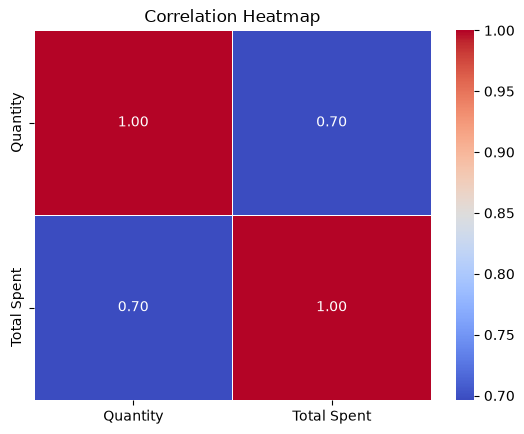

In [18]:
# correlation
correlation_plot = clean_set.iloc[:,[2,4]].corr()

fig, ax = plt.subplots()

sns.heatmap(correlation_plot, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap')
plt.show()